# プレミアリーグ10/17第7節結果

**氏名：［中島悠樹］**

これは完成例です。自分の問い・データ・観察に変えて使ってください。

## 調べたいこと

プレミアリーグ10/17第７節の結果をまとめ シュート数を比較してシュートを打った本数と試合の結果がどうなっているかを分かりやすくしたい

出典：[ESPN（サッカー試合データ）]https://www.espn.com/soccer/／取得日：2026年10月17日／時刻：日本時間



## 試合結果を取り出す

eventsは試合のリスト。一試合の辞書の中にcompetitions、その中にcompetitorsというチームのリストがある。

です。

In [4]:
import matplotlib.pyplot as plt

print("グラフを作る準備ができました")

グラフを作る準備ができました


In [6]:
import os

print(os.getcwd())
print(os.listdir())

[local]\OneDrive\Documents\Programming\week03
['week-03-homework-data-discovery.ipynb', 'week-03-in-class-part-01-lists.ipynb', 'week-03-in-class-part-02-dictionaries.ipynb']


In [7]:
import json

with open(r"[local]\Downloads\sports.json", "r", encoding="utf-8") as file:
    data = json.load(file)

print("読み込み成功！")
print("試合数:", len(data["events"]))

読み込み成功！
試合数: 5


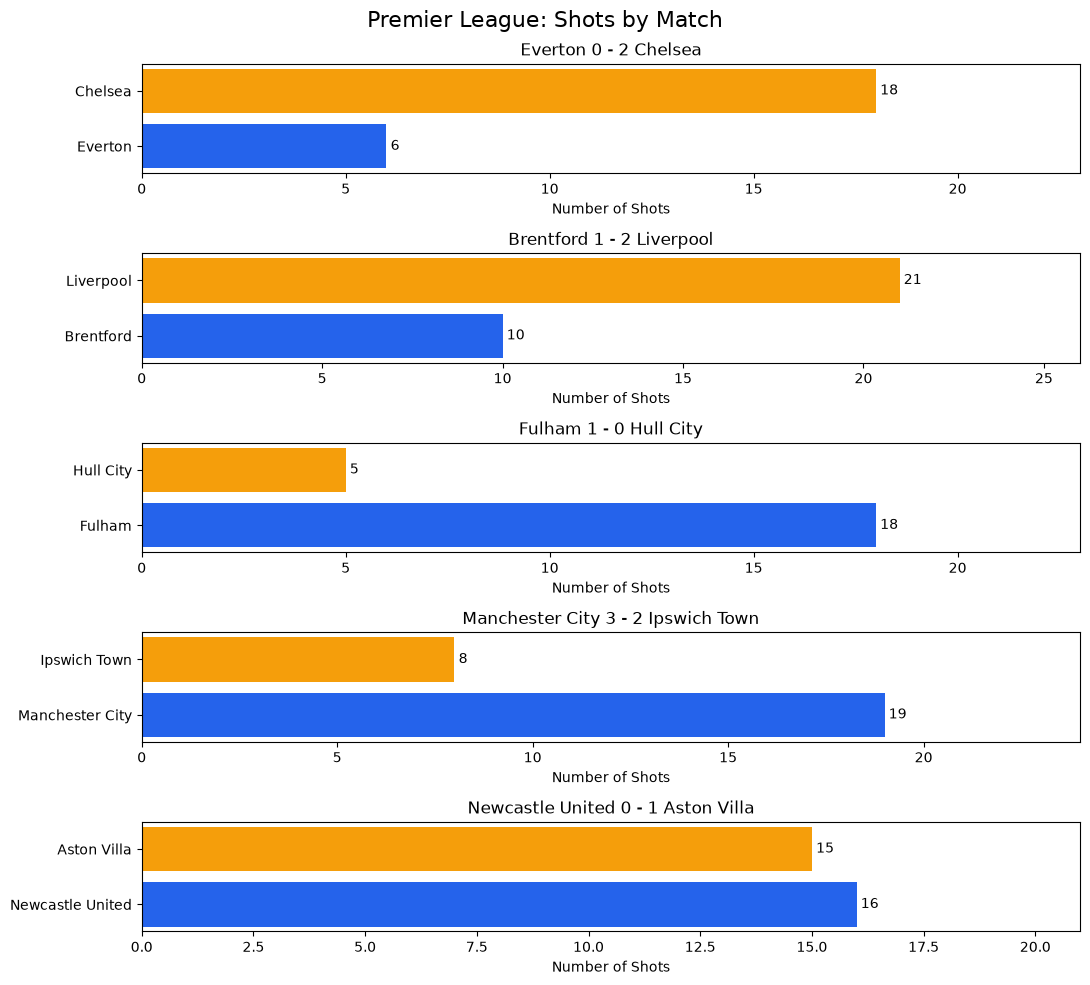

In [18]:
import matplotlib.pyplot as plt

# 日本語ではなく英語のチーム名で表示する
fig, axes = plt.subplots(5, 1, figsize=(11, 10))

# sports.jsonの全試合を順番に処理する
for i, match in enumerate(data["events"]):
    teams = match["competitions"][0]["competitors"]

    team_names = []
    shots = []
    colors = []
    scores = []

    # チーム名、得点、シュート数を取り出す
    for team in teams:
        name = team["team"]["displayName"]
        team_names.append(name)
        scores.append(team["score"])

        # ホームチームは青、アウェイチームはオレンジ
        if team.get("homeAway") == "home":
            colors.append("#2563EB")
        else:
            colors.append("#F59E0B")

        # シュート数を探す
        for stat in team["statistics"]:
            if stat["name"] == "totalShots":
                shots.append(int(stat["displayValue"]))
                break

    # 試合ごとのグラフを作る
    bars = axes[i].barh(
        team_names,
        shots,
        color=colors
    )

    axes[i].set_title(
        f"{team_names[0]} {scores[0]} - "
        f"{scores[1]} {team_names[1]}"
    )
    axes[i].set_xlabel("Number of Shots")
    axes[i].bar_label(bars, padding=3)
    axes[i].set_xlim(0, max(shots) + 5)

# 全体のタイトル
fig.suptitle(
    "Premier League: Shots by Match",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 分かったこと

基本的にシュートをたくさん打っているチームが勝っている。
**確認：** 元のJSONの``で、添字8が17.7、添字14が21.1であることを確かめた。

**限界：** これは予報で、実測ではない。風や雨は調べていない。取得日が変わると値も変わるので、再実行したら観察も書き直す。

## 通信できないときだけ

保存データ`weather-kashiwa-example.json`を同じフォルダに置き、最初のCode Cellを次のコードに置き換えます。2026年10月15日の保存例なので、最新の予報ではありません。

```python
import json

with open("weather-kashiwa-example.json", encoding="utf-8") as file:
    data = json.load(file)
```

## 自分の課題として提出する

自分の問いでAPIデータを読み、何か一つ見せよう。文章の出力だけでもOK。発見・確かめた値・限界・出典URLと取得日を短く書きます。AIを使った場合は、用途を一言添えてください。

**一番上にタイトルと氏名。全Cellを実行し、出力と観察を保存。**

10月21日（水）23:59 JSTまでに、`.ipynb`と必要なファイルをUNIPAへ。